In [1]:
# ===== Imports et configuration =====
import zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", "{:,.3f}".format)

ROOT = Path("..")                      # on suppose que le notebook est dans notebooks/
RAW  = ROOT / "data" / "raw"           # données brutes (lecture seule)
RAW.mkdir(parents=True, exist_ok=True)

In [2]:
# ===== Décompression (une seule fois) =====
for z in ["CSV-01-12.zip", "CSV-03-11.zip"]:
    target = RAW / z.replace(".zip", "")
    if not target.exists():
        print(f"Décompression de {z} ...")
        with zipfile.ZipFile(ROOT / z) as zf:
            zf.extractall(target)
    else:
        print(f"{z} déjà décompressé")

Décompression de CSV-01-12.zip ...
Décompression de CSV-03-11.zip ...


In [3]:
# ===== Inventaire des fichiers =====
files = sorted(RAW.rglob("*.csv"))
inventory = pd.DataFrame({
    "fichier": [f.name for f in files],
    "dossier": [f.parent.name for f in files],
    "taille_Mo": [round(f.stat().st_size / 1e6, 1) for f in files],
})
display(inventory)
print(f"{len(files)} fichiers, {inventory.taille_Mo.sum()/1000:.1f} Go au total")

,fichier,dossier,taille_Mo
0,DrDoS_DNS.csv,01-12,"2,133.300"
1,DrDoS_LDAP.csv,01-12,917.300
2,DrDoS_MSSQL.csv,01-12,"1,889.200"
3,DrDoS_NetBIOS.csv,01-12,"1,697.500"
4,DrDoS_NTP.csv,01-12,645.000
5,DrDoS_SNMP.csv,01-12,"2,172.600"
6,DrDoS_SSDP.csv,01-12,"1,252.700"
7,DrDoS_UDP.csv,01-12,"1,506.000"
8,Syn.csv,01-12,637.300
9,TFTP.csv,01-12,"9,302.000"


18 fichiers, 31.1 Go au total


In [4]:
# ===== Vérifier que tous les fichiers ont les mêmes colonnes =====
def read_header(path):
    cols = pd.read_csv(path, nrows=0).columns
    return [c.strip() for c in cols]          # on enlève les espaces parasites

headers = {f.name: read_header(f) for f in files}
ref = next(iter(headers.values()))
for name, cols in headers.items():
    if cols != ref:
        print(f"Colonnes différentes dans {name} :", set(cols) ^ set(ref))
print("Nombre de colonnes (référence) :", len(ref))

Nombre de colonnes (référence) : 88


In [5]:
# ===== Fonctions de chargement =====
def optimize(df):
    """Réduit la mémoire : float64 -> float32, int64 -> plus petit entier."""
    for c in df.select_dtypes("float64"):
        df[c] = df[c].astype("float32")
    for c in df.select_dtypes("int64"):
        df[c] = pd.to_numeric(df[c], downcast="integer")
    return df

def load_sample(path, frac=0.02, chunksize=500_000):
    """Lit le fichier par morceaux et garde frac % des lignes (reproductible)."""
    parts = []
    for chunk in pd.read_csv(path, chunksize=chunksize, low_memory=False):
        chunk.columns = chunk.columns.str.strip()
        parts.append(optimize(chunk.sample(frac=frac, random_state=42)))
    out = pd.concat(parts, ignore_index=True)
    out["source_file"] = path.name
    return out

# Échantillon de 2 % de chaque fichier, regroupé
df_raw = pd.concat([load_sample(f) for f in files], ignore_index=True)
df = df_raw.copy()                      # df_raw reste intact
print("Échantillon chargé :", df.shape)

Échantillon chargé : (1408554, 89)


In [6]:
# ===== Passage complet par chunks : taille exacte et distribution de la cible =====
from collections import Counter

total_rows = 0
label_counts = Counter()
rows_per_file = {}

for f in files:
    n = 0
    for chunk in pd.read_csv(f, usecols=lambda c: c.strip() == "Label", chunksize=1_000_000):
        chunk.columns = ["Label"]
        n += len(chunk)
        label_counts.update(chunk["Label"].astype(str).str.strip().value_counts().to_dict())
    rows_per_file[f.name] = n
    total_rows += n

print(f"Total de lignes (dataset complet) : {total_rows:,}")
display(pd.Series(rows_per_file, name="lignes").to_frame())

Total de lignes (dataset complet) : 70,427,637


,lignes
DrDoS_DNS.csv,5074413
DrDoS_LDAP.csv,2181542
DrDoS_MSSQL.csv,4524498
DrDoS_NetBIOS.csv,4094986
DrDoS_NTP.csv,1217007
DrDoS_SNMP.csv,5161377
DrDoS_SSDP.csv,2611374
DrDoS_UDP.csv,3136802
Syn.csv,4320541
TFTP.csv,20107827


In [7]:
# ===== Description de l'échantillon =====
print("Dimensions :", df.shape)
df.info()

Dimensions : (1408554, 89)
<class 'pandas.DataFrame'>
RangeIndex: 1408554 entries, 0 to 1408553
Data columns (total 89 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   Unnamed: 0                   1408554 non-null  int32  
 1   Flow ID                      1408554 non-null  str    
 2   Source IP                    1408554 non-null  str    
 3   Source Port                  1408554 non-null  int32  
 4   Destination IP               1408554 non-null  str    
 5   Destination Port             1408554 non-null  int32  
 6   Protocol                     1408554 non-null  int8   
 7   Timestamp                    1408554 non-null  str    
 8   Flow Duration                1408554 non-null  int32  
 9   Total Fwd Packets            1408554 non-null  int32  
 10  Total Backward Packets       1408554 non-null  int16  
 11  Total Length of Fwd Packets  1408554 non-null  float32
 12  Total Length of Bwd Packet

In [8]:
display(df.head())
display(df.tail(3))
display(df.sample(5, random_state=42))

,Unnamed: 0,Flow ID,Source IP,Source Port,Destination IP,Destination Port,Protocol,Timestamp,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Min Packet Length,Max Packet Length,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Header Length.1,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,SimillarHTTP,Inbound,Label,source_file
0,15326,172.16.0.5-192.168.50.1-706-52194-17,172.16.0.5,706,192.168.50.1,52194,17,2018-12-01 11:06:14.995367,1,2,0,"2,944.000",0.000,"1,472.000","1,472.000","1,472.000",0.000,0.000,0.000,0.000,0.000,"2,944,000,000.000","2,000,000.000",1.000,0.000,1.000,1.000,1.000,1.000,0.000,1.000,1.000,0.000,0.000,0.000,0.000,0.000,0,0,0,0,-2,0,"2,000,000.000",0.000,"1,472.000","1,472.000","1,472.000",0.000,0.000,0,0,0,0,0,0,0,0,0.000,"2,208.000","1,472.000",0.000,-2,0,0,0,0,0,0,2,2944,0,0,-1,-1,1,-1,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0,1,DrDoS_DNS,DrDoS_DNS.csv
1,3933,172.16.0.5-192.168.50.1-746-19392-17,172.16.0.5,746,192.168.50.1,19392,17,2018-12-01 11:06:26.165626,49,2,0,"2,944.000",0.000,"1,472.000","1,472.000","1,472.000",0.000,0.000,0.000,0.000,0.000,"60,081,632.000","40,816.328",49.000,0.000,49.000,49.000,49.000,49.000,0.000,49.000,49.000,0.000,0.000,0.000,0.000,0.000,0,0,0,0,-2,0,"40,816.328",0.000,"1,472.000","1,472.000","1,472.000",0.000,0.000,0,0,0,0,0,0,0,0,0.000,"2,208.000","1,472.000",0.000,-2,0,0,0,0,0,0,2,2944,0,0,-1,-1,1,-1,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0,1,DrDoS_DNS,DrDoS_DNS.csv
2,4551,172.16.0.5-192.168.50.1-853-1707-17,172.16.0.5,853,192.168.50.1,1707,17,2018-12-01 11:06:19.172657,2,2,0,"2,944.000",0.000,"1,472.000","1,472.000","1,472.000",0.000,0.000,0.000,0.000,0.000,"1,472,000,000.000","1,000,000.000",2.000,0.000,2.000,2.000,2.000,2.000,0.000,2.000,2.000,0.000,0.000,0.000,0.000,0.000,0,0,0,0,64,0,"1,000,000.000",0.000,"1,472.000","1,472.000","1,472.000",0.000,0.000,0,0,0,0,0,0,0,0,0.000,"2,208.000","1,472.000",0.000,64,0,0,0,0,0,0,2,2944,0,0,-1,-1,1,32,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0,1,DrDoS_DNS,DrDoS_DNS.csv
3,3772,172.16.0.5-192.168.50.1-761-41798-17,172.16.0.5,761,192.168.50.1,41798,17,2018-12-01 11:06:18.321209,1,2,0,"2,944.000",0.000,"1,472.000","1,472.000","1,472.000",0.000,0.000,0.000,0.000,0.000,"2,944,000,000.000","2,000,000.000",1.000,0.000,1.000,1.000,1.000,1.000,0.000,1.000,1.000,0.000,0.000,0.000,0.000,0.000,0,0,0,0,2114,0,"2,000,000.000",0.000,"1,472.000","1,472.000","1,472.000",0.000,0.000,0,0,0,0,0,0,0,0,0.000,"2,208.000","1,472.000",0.000,2114,0,0,0,0,0,0,2,2944,0,0,-1,-1,1,1057,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0,1,DrDoS_DNS,DrDoS_DNS.csv
4,19804,172.16.0.5-192.168.50.1-995-4498-17,172.16.0.5,995,192.168.50.1,4498,17,2018-12-01 11:06:51.244955,1,2,0,"2,944.000",0.000,"1,472.000","1,472.000","1,472.000",0.000,0.000,0.000,0.000,0.000,"2,944,000,000.000","2,000,000.000",1.000,0.000,1.000,1.000,1.000,1.000,0.000,1.000,1.000,0.000,0.000,0.000,0.000,0.

,Unnamed: 0,Flow ID,Source IP,Source Port,Destination IP,Destination Port,Protocol,Timestamp,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Min Packet Length,Max Packet Length,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Header Length.1,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,SimillarHTTP,Inbound,Label,source_file
1408551,208350,172.16.0.5-192.168.50.4-29172-32093-6,172.16.0.5,29172,192.168.50.4,32093,6,2018-11-03 11:30:24.754087,49,2,0,12.000,0.000,6.000,6.000,6.000,0.000,0.000,0.000,0.000,0.000,"244,897.953","40,816.328",49.000,0.000,49.000,49.000,49.000,49.000,0.000,49.000,49.000,0.000,0.000,0.000,0.000,0.000,0,0,0,0,40,0,"40,816.328",0.000,6.000,6.000,6.000,0.000,0.000,0,0,0,0,1,0,0,0,0.000,9.000,6.000,0.000,40,0,0,0,0,0,0,2,12,0,0,5840,-1,1,20,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0,1,Syn,UDPLag.csv
1408552,472690,172.16.0.5-192.168.50.4-21855-34862-6,172.16.0.5,21855,192.168.50.4,34862,6,2018-11-03 11:30:16.247936,1,2,0,12.000,0.000,6.000,6.000,6.000,0.000,0.000,0.000,0.000,0.000,"12,000,000.000","2,000,000.000",1.000,0.000,1.000,1.000,1.000,1.000,0.000,1.000,1.000,0.000,0.000,0.000,0.000,0.000,0,0,0,0,40,0,"2,000,000.000",0.000,6.000,6.000,6.000,0.000,0.000,0,0,0,0,1,0,0,0,0.000,9.000,6.000,0.000,40,0,0,0,0,0,0,2,12,0,0,5840,-1,1,20,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0,1,Syn,UDPLag.csv
1408553,221175,172.16.0.5-192.168.50.4-17774-12835-6,172.16.0.5,17774,192.168.50.4,12835,6,2018-11-03 11:30:08.104734,68,2,2,12.000,12.000,6.000,6.000,6.000,0.000,6.000,6.000,6.000,0.000,"352,941.188","58,823.531",22.667,37.528,66.000,1.000,1.000,1.000,0.000,1.000,1.000,1.000,1.000,0.000,1.000,1.000,0,0,0,0,40,40,"29,411.766","29,411.766",6.000,6.000,6.000,0.000,0.000,0,0,0,0,1,0,0,0,1.000,7.500,6.000,6.000,40,0,0,0,0,0,0,2,12,2,12,5840,0,1,20,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0,1,Syn,UDPLag.csv


,Unnamed: 0,Flow ID,Source IP,Source Port,Destination IP,Destination Port,Protocol,Timestamp,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Min Packet Length,Max Packet Length,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Header Length.1,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,SimillarHTTP,Inbound,Label,source_file
1133661,74445,172.16.0.5-192.168.50.4-61850-30886-17,172.16.0.5,61850,192.168.50.4,30886,17,2018-11-03 10:41:21.767742,1,2,0,"1,116.000",0.000,558.000,558.000,558.000,0.000,0.000,0.000,0.000,0.000,"1,116,000,000.000","2,000,000.000",1.000,0.000,1.000,1.000,1.000,1.000,0.000,1.000,1.000,0.000,0.000,0.000,0.000,0.000,0,0,0,0,0,0,"2,000,000.000",0.000,558.000,558.000,558.000,0.000,0.000,0,0,0,0,0,0,0,0,0.000,837.000,558.000,0.000,0,0,0,0,0,0,0,2,1116,0,0,-1,-1,1,0,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0,1,MSSQL,MSSQL.csv
548419,119917,172.16.0.5-192.168.50.1-51699-9888-17,172.16.0.5,51699,192.168.50.1,9888,17,2018-12-01 13:03:20.311095,47,2,0,766.000,0.000,383.000,383.000,383.000,0.000,0.000,0.000,0.000,0.000,"16,297,872.000","42,553.191",47.000,0.000,47.000,47.000,47.000,47.000,0.000,47.000,47.000,0.000,0.000,0.000,0.000,0.000,0,0,0,0,16,0,"42,553.191",0.000,383.000,383.000,383.000,0.000,0.000,0,0,0,0,0,0,0,0,0.000,574.500,383.000,0.000,16,0,0,0,0,0,0,2,766,0,0,-1,-1,1,8,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0,1,DrDoS_UDP,DrDoS_UDP.csv
1335093,50716,172.16.0.5-192.168.50.4-50269-34407-17,172.16.0.5,50269,192.168.50.4,34407,17,2018-11-03 10:55:47.770689,1,2,0,750.000,0.000,375.000,375.000,375.000,0.000,0.000,0.000,0.000,0.000,"750,000,000.000","2,000,000.000",1.000,0.000,1.000,1.000,1.000,1.000,0.000,1.000,1.000,0.000,0.000,0.000,0.000,0.000,0,0,0,0,40,0,"2,000,000.000",0.000,375.000,375.000,375.000,0.000,0.000,0,0,0,0,0,0,0,0,0.000,562.500,375.000,0.000,40,0,0,0,0,0,0,2,750,0,0,-1,-1,1,20,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0,1,UDP,UDP.csv
1401291,90492,172.16.0.5-192.168.50.4-58798-29878-17,172.16.0.5,58798,192.168.50.4,29878,17,2018-11-03 11:01:46.203440,1,2,0,766.000,0.000,383.000,383.000,383.000,0.000,0.000,0.000,0.000,0.000,"766,000,000.000","2,000,000.000",1.000,0.000,1.000,1.000,1.000,1.000,0.000,1.000,1.000,0.000,0.000,0.000,0.000,0.000,0,0,0,0,40,0,"2,000,000.000",0.000,383.000,383.000,383.000,0.000,0.000,0,0,0,0,0,0,0,0,0.000,574.500,383.000,0.000,40,0,0,0,0,0,0,2,766,0,0,-1,-1,1,20,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0,1,UDP,UDPLag.csv
517577,113872,172.16.0.5-192.168.50.1-44894-58854-17,172.16.0.5,44894,192.168.50.1,58854,17,2018-12-01 12:58:56.824650,108682,4,0,"1,438.000",0.000,389.000,330.000,359.500,34.064,0.000,0.000,0.000,0.000,"13,231.262",36.805,"36,227.332","62,745.852","108,680.000",1.000,"108,682.000","36,227.332","62,745.852","108,680.000",1.000,0.000,0.000,0.000,0.000,0.000,0,0,0,0,794,0,36.805,0.000,330.000,389.000,353.600,32.316,"1,044.300",0,0,0,0,0,0,0,0,0.000,442.0

In [9]:
print(df.dtypes.value_counts())
print(f"\nMémoire : {df.memory_usage(deep=True).sum()/1e6:.0f} Mo")

# Cardinalité de chaque colonne
card = df.nunique().sort_values()
display(card.to_frame("nb_valeurs_distinctes").T)

float32    45
int8       20
int32      12
str         6
int16       3
int64       2
object      1
Name: count, dtype: int64

Mémoire : 661 Mo


,FIN Flag Count,PSH Flag Count,Fwd Avg Bytes/Bulk,ECE Flag Count,Fwd URG Flags,Bwd URG Flags,Bwd PSH Flags,Fwd Avg Packets/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bytes/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bulk Rate,ACK Flag Count,URG Flag Count,RST Flag Count,Fwd PSH Flags,SYN Flag Count,CWE Flag Count,Inbound,Protocol,Down/Up Ratio,source_file,Label,SimillarHTTP,Bwd IAT Min,Total Backward Packets,Subflow Bwd Packets,Bwd Packet Length Min,act_data_pkt_fwd,Bwd Header Length,Subflow Fwd Packets,Total Fwd Packets,Source IP,Bwd Packet Length Max,Init_Win_bytes_backward,Fwd IAT Min,Init_Win_bytes_forward,Bwd Packet Length Std,Destination IP,Flow IAT Min,Total Length of Bwd Packets,Subflow Bwd Bytes,Avg Bwd Segment Size,Bwd Packet Length Mean,Active Min,Fwd Packet Length Std,Packet Length Std,Packet Length Variance,Min Packet Length,Fwd Packet Length Min,Fwd Packet Length Max,Max Packet Length,min_seg_size_forward,Fwd Packet Length Mean,Avg Fwd Segment Size,Total Length of Fwd Packets,Subflow Fwd Bytes,Active Max,Packet Length Mean,Fwd Header Length.1,Fwd Header Length,Average Packet Size,Active Mean,Active Std,Bwd IAT Std,Bwd IAT Max,Bwd IAT Total,Bwd IAT Mean,Bwd Packets/s,Idle Std,Idle Min,Idle Max,Idle Mean,Source Port,Destination Port,Fwd IAT Max,Flow IAT Max,Fwd IAT Total,Flow Duration,Fwd Packets/s,Flow Packets/s,Fwd IAT Mean,Flow IAT Mean,Flow Bytes/s,Fwd IAT Std,Flow IAT Std,Unnamed: 0,Flow ID,Timestamp
nb_valeurs_distinctes,1,1,1,1,1,1,1,1,1,1,1,1,2,2,2,2,2,2,2,3,10,16,19,57,80,103,103,127,201,208,211,211,221,248,277,282,327,376,383,390,453,453,485,485,497,975,1142,1142,1251,1252,1322,1363,1401,2137,2137,2167,2167,2374,2558,2786,2786,2956,3417,6444,7129,7171,7177,7194,12421,13695,15471,15498,15507,60922,65535,73662,74513,104046,104974,114241,114246,115034,115998,128495,165912,167936,302025,1382167,1408309


In [10]:
# ===== Repérage des rôles des colonnes =====
constantes   = card[card <= 1].index.tolist()
identifiants = [c for c in df.columns
                if any(k in c.lower() for k in ["flow id", "ip", "unnamed", "timestamp"])]
cibles       = ["Label"]
colonnes_objet = df.select_dtypes("object").columns.tolist()

print("Colonnes constantes   :", constantes)
print("Identifiants / réseau :", identifiants)
print("Colonnes texte        :", colonnes_objet)

Colonnes constantes   : ['FIN Flag Count', 'PSH Flag Count', 'Fwd Avg Bytes/Bulk', 'ECE Flag Count', 'Fwd URG Flags', 'Bwd URG Flags', 'Bwd PSH Flags', 'Fwd Avg Packets/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bytes/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bulk Rate']
Identifiants / réseau : ['Unnamed: 0', 'Flow ID', 'Source IP', 'Destination IP', 'Timestamp']
Colonnes texte        : ['Flow ID', 'Source IP', 'Destination IP', 'Timestamp', 'SimillarHTTP', 'Label', 'source_file']


C:\Users\DELL\AppData\Local\Temp\ipykernel_1664\3609542303.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  colonnes_objet = df.select_dtypes("object").columns.tolist()


In [12]:
dico = pd.DataFrame({
    "colonne": df.columns,
    "type_pandas": df.dtypes.astype(str).values,
    "nb_distincts": df.nunique().values,
    "exemple": [df[c].dropna().iloc[0] if df[c].notna().any() else None for c in df.columns],
    "role": "feature",
})
dico.loc[dico.colonne.isin(identifiants), "role"] = "identifiant (à exclure)"
dico.loc[dico.colonne.isin(constantes),   "role"] = "constante (inutile)"
dico.loc[dico.colonne == "Label",         "role"] = "cible"
dico.to_csv(ROOT / "data" / "dictionnaire_donnees.csv", index=False)
display(dico)

,colonne,type_pandas,nb_distincts,exemple,role
0,Unnamed: 0,int32,302025,15326,identifiant (à exclure)
1,Flow ID,str,1382167,172.16.0.5-192.168.50.1-706-52194-17,identifiant (à exclure)
2,Source IP,str,221,172.16.0.5,identifiant (à exclure)
3,Source Port,int32,60922,706,feature
4,Destination IP,str,383,192.168.50.1,identifiant (à exclure)
...,...,...,...,...,...
84,Idle Min,float32,15471,0.000,feature
85,SimillarHTTP,object,57,0,feature
86,Inbound,int8,2,1,feature
87,Label,str,19,DrDoS_DNS,cible


In [13]:
# ===== Numériques =====
num_cols = df.select_dtypes("number").columns
display(df[num_cols].describe().T)

c:\Users\DELL\Desktop\Projet_DDoS\.venv\Lib\site-packages\pandas\core\nanops.py:1028: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
c:\Users\DELL\Desktop\Projet_DDoS\.venv\Lib\site-packages\pandas\core\nanops.py:1028: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,"1,408,554.000","90,075.498","115,872.812",0.000,"21,306.000","53,683.000","105,106.750","805,202.000"
Source Port,"1,408,554.000","31,769.562","26,333.750",0.000,876.000,"36,079.000","61,850.000","65,532.000"
Destination Port,"1,408,554.000","32,799.574","18,905.388",0.000,"16,444.000","32,820.000","49,180.000","65,535.000"
Protocol,"1,408,554.000",15.902,3.299,0.000,17.000,17.000,17.000,17.000
Flow Duration,"1,408,554.000","1,192,814.488","6,500,833.551",0.000,1.000,1.000,126.000,"119,999,461.000"
...,...,...,...,...,...,...,...,...
Idle Mean,"1,408,554.000","171,576.938","1,771,333.000",0.000,0.000,0.000,0.000,"114,939,656.000"
Idle Std,"1,408,554.000","49,001.270","603,705.125",0.000,0.000,0.000,0.000,"43,939,008.000"
Idle Max,"1,408,554.000","228,373.219","2,342,711.750",0.000,0.000,0.000,0.000,"114,939,656.000"
Idle Min,"1,408,554.000","125,380.250","1,397,963.250",0.000,0.000,0.000,0.000,"114,939,656.000"


In [14]:
# ===== Catégorielles =====
display(df.describe(include="object").T)

for c in ["Label", "source_file"]:
    print(f"\n--- {c} ---")
    print(df[c].value_counts(dropna=False))

C:\Users\DELL\AppData\Local\Temp\ipykernel_1664\3236246207.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include="object").T)


,count,unique,top,freq
Flow ID,1408554,1382167,192.168.50.253-224.0.0.5-0-0-0,23
Source IP,1408554,221,172.16.0.5,1405803
Destination IP,1408554,383,192.168.50.1,999793
Timestamp,1408554,1408309,2018-12-01 13:41:10.641509,2
SimillarHTTP,1408554,57,0,1231498
Label,1408554,19,TFTP,401634
source_file,1408554,16,TFTP.csv,402157



--- Label ---
Label
TFTP             401634
Syn              129514
MSSQL            115745
DrDoS_SNMP       103197
DrDoS_DNS        101417
DrDoS_MSSQL       90458
DrDoS_NetBIOS     81868
UDP               77318
NetBIOS           73123
DrDoS_UDP         62703
DrDoS_SSDP        52212
DrDoS_LDAP        43605
LDAP              38332
DrDoS_NTP         24055
UDP-lag            7319
Portmap            3741
BENIGN             2269
UDPLag               34
WebDDoS              10
Name: count, dtype: int64

--- source_file ---
source_file
TFTP.csv             402157
Syn.csv              118065
MSSQL.csv            115516
DrDoS_SNMP.csv       103228
DrDoS_DNS.csv        101488
DrDoS_MSSQL.csv       90490
DrDoS_NetBIOS.csv     81900
UDP.csv               75644
NetBIOS.csv           69118
DrDoS_UDP.csv         62736
DrDoS_SSDP.csv        52227
DrDoS_LDAP.csv        43631
LDAP.csv              42265
DrDoS_NTP.csv         24340
UDPLag.csv            21915
Portmap.csv            3834
Name: count, dty

,nombre,pourcentage
TFTP,20082580,28.515
Syn,6473789,9.192
MSSQL,5787453,8.218
DrDoS_SNMP,5159870,7.326
DrDoS_DNS,5071011,7.200
DrDoS_MSSQL,4522492,6.421
DrDoS_NetBIOS,4093279,5.812
UDP,3867155,5.491
NetBIOS,3657497,5.193
DrDoS_UDP,3134645,4.451


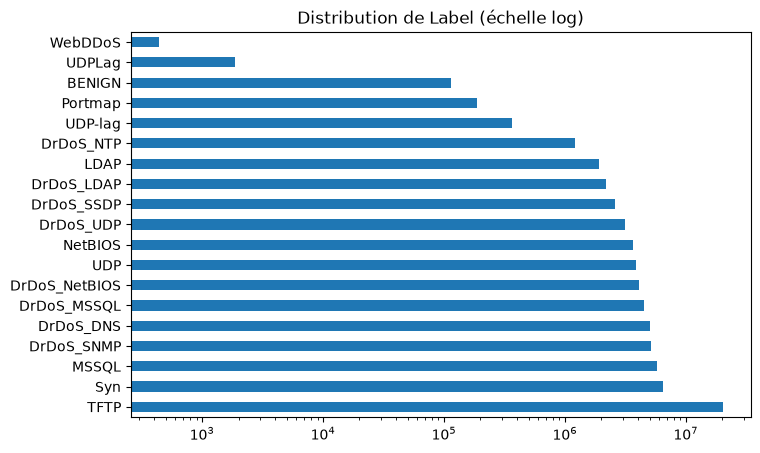

In [15]:
# ===== Distribution exacte de la cible (dataset complet) =====
labels = pd.Series(label_counts, name="nombre").sort_values(ascending=False).to_frame()
labels["pourcentage"] = (labels["nombre"] / labels["nombre"].sum() * 100).round(3)
display(labels)

labels["nombre"].plot(kind="barh", figsize=(8, 5), logx=True, title="Distribution de Label (échelle log)")
plt.show()

In [16]:
# ===== Asymétrie et aplatissement =====
shape_stats = pd.DataFrame({
    "skew": df[num_cols].replace([np.inf, -np.inf], np.nan).skew(),
    "kurtosis": df[num_cols].replace([np.inf, -np.inf], np.nan).kurt(),
}).sort_values("skew", key=abs, ascending=False)
display(shape_stats.head(15))

,skew,kurtosis
Total Length of Bwd Packets,615.690,"448,953.844"
Subflow Bwd Bytes,615.690,"448,953.868"
Flow IAT Min,614.175,"425,533.062"
Fwd IAT Min,608.674,"419,892.750"
Bwd Header Length,-593.411,"352,134.750"
Subflow Fwd Packets,589.019,"350,883.845"
Total Fwd Packets,589.019,"350,883.845"
Total Backward Packets,461.101,"284,130.621"
Subflow Bwd Packets,461.101,"284,130.621"
SYN Flag Count,195.105,"38,064.162"


In [17]:
# ===== Écart moyenne / médiane (signe d'asymétrie ou d'outliers) =====
tmp = df[num_cols].replace([np.inf, -np.inf], np.nan)
ecart = pd.DataFrame({"moyenne": tmp.mean(), "mediane": tmp.median()})
ecart["ratio"] = ecart["moyenne"] / ecart["mediane"].replace(0, np.nan)
display(ecart.sort_values("ratio", key=abs, ascending=False).head(15))

,moyenne,mediane,ratio
min_seg_size_forward,"-44,268,230.779",14.000,"-3,162,016.484"
Fwd Header Length,"-103,862,776.665",40.000,"-2,596,569.417"
Fwd Header Length.1,"-103,862,776.665",40.000,"-2,596,569.417"
Flow Duration,"1,192,814.488",1.000,"1,192,814.488"
Fwd IAT Total,"1,192,289.750",1.000,"1,192,289.750"
Flow IAT Max,"682,751.250",1.000,"682,751.250"
Fwd IAT Max,"682,451.625",1.000,"682,451.625"
Fwd IAT Mean,"226,270.516",1.000,"226,270.516"
Flow IAT Mean,"212,693.359",1.000,"212,693.359"
Init_Win_bytes_forward,589.935,-1.000,-589.935


In [18]:
# ===== 4.1 Valeurs manquantes =====
miss = pd.DataFrame({
    "nb_manquants": df.isnull().sum(),
    "pourcentage": df.isnull().mean() * 100,
}).query("nb_manquants > 0").sort_values("pourcentage", ascending=False)
display(miss if len(miss) else "Aucune valeur manquante (NaN) dans l'échantillon")

,nb_manquants,pourcentage
Flow Bytes/s,5040,0.358


In [19]:
# ===== 4.2 Valeurs infinies (fréquentes dans Flow Bytes/s et Flow Packets/s) =====
inf_counts = np.isinf(df[num_cols]).sum()
display(inf_counts[inf_counts > 0].to_frame("nb_inf"))

,nb_inf
Flow Bytes/s,38581
Flow Packets/s,43621


In [20]:
# ===== 4.3 Doublons =====
print("Doublons exacts (échantillon) :", df.drop(columns="source_file").duplicated().sum())

# Doublons partiels : même Flow ID, comportement différent
if "Flow ID" in df.columns:
    print("Flow ID répétés :", df["Flow ID"].duplicated().sum())

Doublons exacts (échantillon) : 212
Flow ID répétés : 26387


In [ ]:
# ===== 4.4 Outliers : méthode IQR =====
def iqr_report(s):
    s = s.replace([np.inf, -np.inf], np.nan).dropna()
    q1, q3 = s.quantile([.25, .75])
    i = q3 - q1
    n = ((s < q1 - 1.5*i) | (s > q3 + 1.5*i)).sum()
    return pd.Series({"q1": q1, "q3": q3, "nb_outliers": n, "pct": n / len(s) * 100})

outliers = df[num_cols].apply(iqr_report).T.sort_values("pct", ascending=False)
display(outliers.head(15))

,q1,q3,nb_outliers,pct
Max Packet Length,375.000,548.000,"439,417.000",31.196
Fwd Packet Length Max,375.000,548.000,"439,337.000",31.191
Avg Fwd Segment Size,349.500,548.000,"436,611.000",30.997
Fwd Packet Length Mean,349.500,548.000,"436,611.000",30.997
Packet Length Mean,345.600,548.000,"435,828.000",30.942
Fwd IAT Min,1.000,1.000,"421,003.000",29.889
Flow IAT Min,1.000,1.000,"419,795.000",29.803
act_data_pkt_fwd,1.000,1.000,"387,643.000",27.521
Total Fwd Packets,2.000,2.000,"350,898.000",24.912
Subflow Fwd Packets,2.000,2.000,"350,898.000",24.912


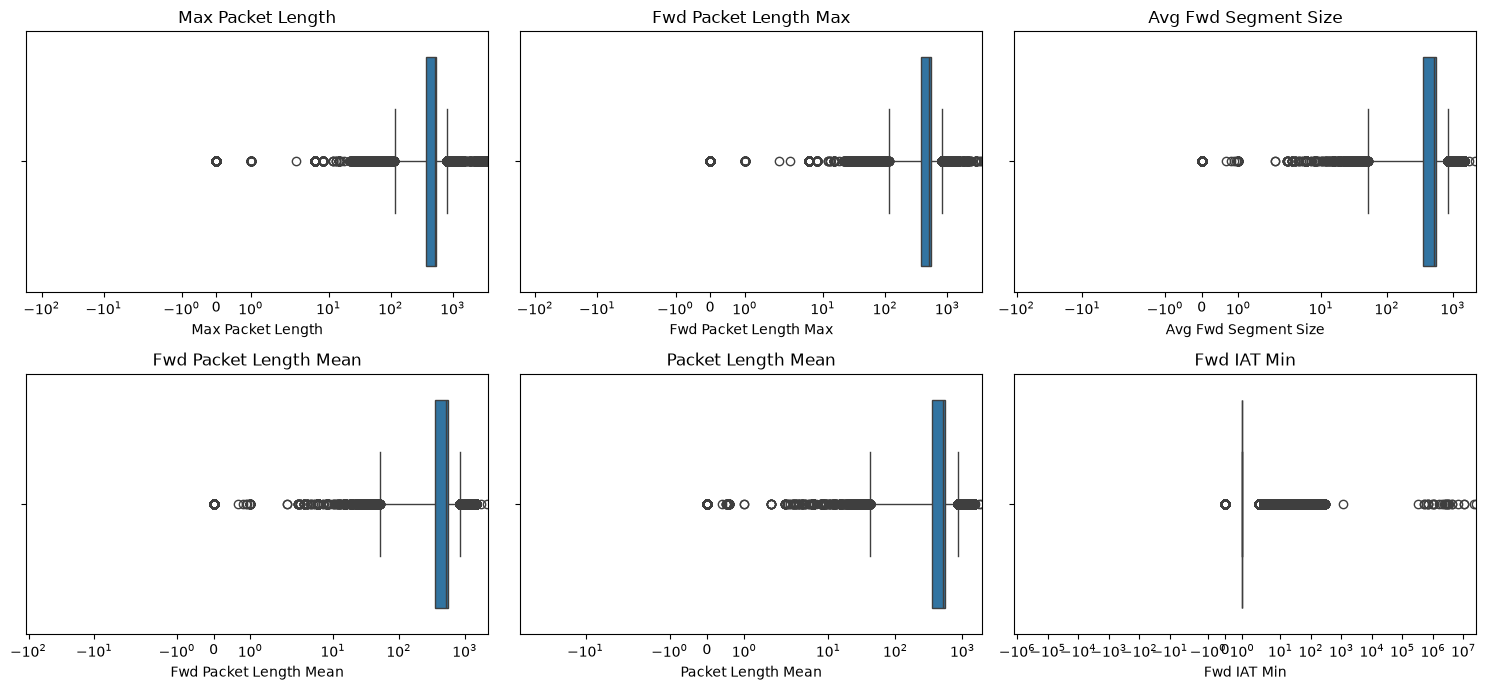

In [22]:
# Boxplots des variables les plus touchées (échelle log pour la lisibilité)
top = outliers.head(6).index
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, c in zip(axes.ravel(), top):
    sns.boxplot(x=df[c].replace([np.inf, -np.inf], np.nan).dropna(), ax=ax)
    ax.set_title(c); ax.set_xscale("symlog")
plt.tight_layout(); plt.show()

In [24]:
# ===== 4.5 Valeurs impossibles / incohérences =====
# Valeurs négatives dans des colonnes qui doivent être >= 0 (durées, compteurs, tailles)
neg = (df[num_cols] < 0).sum()
display(neg[neg > 0].sort_values(ascending=False).to_frame("nb_negatifs"))

,nb_negatifs
Init_Win_bytes_backward,1361352
Init_Win_bytes_forward,1268002
min_seg_size_forward,227337
Fwd Header Length,175717
Fwd Header Length.1,175717
Bwd Header Length,5


In [25]:
# Cohérence entre colonnes (adapter les noms si besoin)
checks = {}
if {"Total Fwd Packets", "Total Backward Packets"} <= set(df.columns):
    checks["paquets totaux = 0"] = ((df["Total Fwd Packets"] + df["Total Backward Packets"]) == 0).sum()
if {"Min Packet Length", "Max Packet Length"} <= set(df.columns):
    checks["min > max (taille paquet)"] = (df["Min Packet Length"] > df["Max Packet Length"]).sum()
if "Flow Duration" in df.columns:
    checks["durée du flux <= 0"] = (df["Flow Duration"] <= 0).sum()
display(pd.Series(checks, name="nb_lignes_incoherentes").to_frame())

,nb_lignes_incoherentes
paquets totaux = 0,0
min > max (taille paquet),0
durée du flux <= 0,43621


In [26]:
# ===== 4.6 Types erronés et formats =====
# Colonnes texte qui devraient être numériques ou dates
for c in colonnes_objet:
    print(f"{c:25s} | exemples : {df[c].dropna().unique()[:3]}")

if "Timestamp" in df.columns:
    ts = pd.to_datetime(df["Timestamp"], errors="coerce")
    print("\nTimestamp illisibles :", ts.isna().sum())
    print("Période couverte     :", ts.min(), "->", ts.max())

Flow ID                   | exemples : <ArrowStringArray>
['172.16.0.5-192.168.50.1-706-52194-17',
 '172.16.0.5-192.168.50.1-746-19392-17',
  '172.16.0.5-192.168.50.1-853-1707-17']
Length: 3, dtype: str
Source IP                 | exemples : <ArrowStringArray>
['172.16.0.5', '192.168.50.1', '192.168.50.7']
Length: 3, dtype: str
Destination IP            | exemples : <ArrowStringArray>
['192.168.50.1', '172.16.0.5', '74.208.236.171']
Length: 3, dtype: str
Timestamp                 | exemples : <ArrowStringArray>
['2018-12-01 11:06:14.995367', '2018-12-01 11:06:26.165626',
 '2018-12-01 11:06:19.172657']
Length: 3, dtype: str
SimillarHTTP              | exemples : ['0'
 'drmokhberi.ca/wp-content/themes/donovan/assets/css/custom-fonts.css?ver=20180413'
 '205.174.165.72null']
Label                     | exemples : <ArrowStringArray>
['DrDoS_DNS', 'BENIGN', 'DrDoS_LDAP']
Length: 3, dtype: str
source_file               | exemples : <ArrowStringArray>
['DrDoS_DNS.csv', 'DrDoS_LDAP.csv', 'DrDoS

In [27]:
# ===== 4.7 Cohérence de la cible =====
print("Modalités brutes de Label :")
print(sorted(df["Label"].astype(str).unique()))

# Variantes d'écriture (espaces, casse) qui devraient être regroupées
norm = df["Label"].astype(str).str.strip().str.lower()
print("\nAvant normalisation :", df["Label"].nunique(), "| Après :", norm.nunique())

Modalités brutes de Label :
['BENIGN', 'DrDoS_DNS', 'DrDoS_LDAP', 'DrDoS_MSSQL', 'DrDoS_NTP', 'DrDoS_NetBIOS', 'DrDoS_SNMP', 'DrDoS_SSDP', 'DrDoS_UDP', 'LDAP', 'MSSQL', 'NetBIOS', 'Portmap', 'Syn', 'TFTP', 'UDP', 'UDP-lag', 'UDPLag', 'WebDDoS']

Avant normalisation : 19 | Après : 19


In [28]:
# ===== 4.8 Colonnes constantes ou quasi constantes =====
quasi = [c for c in num_cols if df[c].value_counts(normalize=True, dropna=False).iloc[0] > 0.99]
print("Constantes          :", constantes)
print("Quasi constantes >99% :", quasi)

Constantes          : ['FIN Flag Count', 'PSH Flag Count', 'Fwd Avg Bytes/Bulk', 'ECE Flag Count', 'Fwd URG Flags', 'Bwd URG Flags', 'Bwd PSH Flags', 'Fwd Avg Packets/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bytes/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bulk Rate']
Quasi constantes >99% : ['Bwd Packet Length Std', 'Bwd IAT Std', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'URG Flag Count', 'CWE Flag Count', 'ECE Flag Count', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate', 'Active Std', 'Idle Std', 'Inbound']


In [29]:
# ===== 4.9 Rapport de qualité final =====
rapport = pd.DataFrame([
    ["Valeurs manquantes (NaN)", "colonnes concernées", int(df.isnull().sum().sum())],
    ["Valeurs infinies",          "débits",               int(inf_counts.sum())],
    ["Doublons exacts",           "toutes",               int(df.drop(columns='source_file').duplicated().sum())],
    ["Valeurs négatives",         "colonnes numériques",  int(neg.sum())],
    ["Colonnes constantes",       "toutes",               len(constantes)],
    ["Colonnes quasi constantes", "toutes",               len(quasi)],
    ["Colonnes identifiants",     "toutes",               len(identifiants)],
], columns=["problème", "où", "quantité"])
rapport["% des lignes"] = (rapport["quantité"] / len(df) * 100).round(3)
display(rapport)
rapport.to_csv(ROOT / "data" / "rapport_qualite.csv", index=False)

,problème,où,quantité,% des lignes
0,Valeurs manquantes (NaN),colonnes concernées,5040,0.358
1,Valeurs infinies,débits,82202,5.836
2,Doublons exacts,toutes,212,0.015
3,Valeurs négatives,colonnes numériques,3208130,227.761
4,Colonnes constantes,toutes,12,0.001
5,Colonnes quasi constantes,toutes,22,0.002
6,Colonnes identifiants,toutes,5,0.000
